# Radiomics results and error analysis

Compare the saved five-class experiments, understand their errors, and verify repeated LNDb CTs. No models are retrained and no data, folds or submissions are changed.

The target is the half-up-rounded mean of the readers' malignancy ratings, including class 3. These are subjective ratings, not confirmed cancer diagnoses. All performance numbers below use **out-of-fold (OOF) predictions** on LNDb. Except for the LNDb-only experiments, each fold was trained on four LNDb folds plus all LIDC. A final model fitted on all training data must not be used to recreate validation predictions.

Run from the repository root or `notebooks/`. Change `LNDB_DIR` below if the original ZIPs are elsewhere. The SHA-256 section first shortlists candidates using ZIP metadata, then decompresses only those candidates.

In [1]:
import ast
import hashlib
from pathlib import Path
from zipfile import ZipFile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score, confusion_matrix, f1_score, mean_absolute_error, precision_score, recall_score

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
LNDB_DIR = Path.home() / 'Downloads/LNDb'
TARGET = 'target_classification_mean'
KEYS = ['LNDbID', 'FindingID']
CLASSES = [1, 2, 3, 4, 5]
METRICS = ['balanced_accuracy', 'macro_f1', 'qwk', 'mae']
BASE = 'lidc_circle_r21_hu_lndb_circle_r11_hu'
BASELINE = f'rf_{BASE}_balanced'
CHOSEN = 'rf_lidc_circle_r11_hu_lndb_circle_r6_hu_balanced'
SMOTE_RUN = f'rf_{BASE}_smote'
pd.set_option('display.max_columns', 12)

## 1. Are the experiments comparable?

Check that every saved run predicts the same findings, with the same targets and saved folds. Recalculate the four overall metrics from those predictions, rather than averaging fold metrics. Models without five-class validation CSVs are not included.

In [2]:
targets = pd.read_csv(ROOT / 'data/processed/lndb_nodule_targets.csv').rename(columns={'NoduleID': 'FindingID'})
patient_folds = pd.read_csv(ROOT / 'data/processed/lndb_patient_folds.csv')
reference = targets.merge(patient_folds, on='LNDbID', validate='many_to_one')
reference = reference[KEYS + ['fold', TARGET]].sort_values(KEYS).reset_index(drop=True)
predictions, fold_scores, rows = {}, {}, {}
for path in sorted((ROOT / 'models').glob('*/metrics.csv')):
    name = path.parent.name
    p = pd.read_csv(path.parent / 'validation_predictions.csv').sort_values(KEYS).reset_index(drop=True)
    pd.testing.assert_frame_equal(p[reference.columns], reference)
    assert not p.duplicated(KEYS).any() and p.prediction.isin(CLASSES).all(), name
    y, predicted = p[TARGET], p.prediction
    scores = pd.Series({
        'balanced_accuracy': balanced_accuracy_score(y, predicted),
        'macro_f1': f1_score(y, predicted, labels=CLASSES, average='macro', zero_division=0),
        'qwk': cohen_kappa_score(y, predicted, labels=CLASSES, weights='quadratic'),
        'mae': mean_absolute_error(y, predicted),
    })
    stored = pd.read_csv(path)
    overall = stored.loc[stored.fold.eq('overall_oof'), METRICS]
    assert len(overall) == 1, name
    np.testing.assert_allclose(overall.iloc[0], scores[METRICS], rtol=0, atol=1e-12)
    folds = stored.loc[stored.fold.ne('overall_oof')].copy()
    folds['fold'] = folds['fold'].astype(int)
    assert sorted(folds.fold.tolist()) == sorted(reference.fold.unique().tolist()), name
    predictions[name], fold_scores[name], rows[name] = p, folds.set_index('fold')[METRICS], scores
results = pd.DataFrame.from_dict(rows, orient='index')[METRICS]
print(f'{len(results)} experiments, {len(reference)} findings, {reference.LNDbID.nunique()} CT IDs, {reference.fold.nunique()} folds')
print('PASS: identical validation IDs, targets and folds, and recomputed overall metrics.')

17 experiments, 765 findings, 212 CT IDs, 5 folds
PASS: identical validation IDs, targets and folds, and recomputed overall metrics.


### Overall results

- **Balanced accuracy:** average recall of the five classes. Higher is better.
- **Macro F1:** balances precision and recall, giving every class equal importance. Higher is better.
- **QWK:** agreement that accounts for the distance between classes. Higher is better.
- **MAE:** average absolute class error. Lower is better.

The table is sorted by macro F1 for readability, not by an invented combined score. The best run can differ between metrics. `Original` means 93 unfiltered-image features. The other runs start from 930 features, with optional training-fold feature selection. All current runs use original HU without clipping.

In [3]:
imbalance_runs = {
    f'rf_{BASE}': 'RF, unweighted',
    BASELINE: 'RF, balanced weights',
    f'rf_{BASE}_balanced_k100': 'RF, balanced weights, k=100',
    SMOTE_RUN: 'RF, SMOTE',
    f'rf_{BASE}_k100_smote': 'RF, SMOTE, k=100',
    f'rf_{BASE}_k500_smote': 'RF, SMOTE, k=500',
    f'brf_{BASE}': 'Balanced RF',
    'rf_lndb_circle_r11_hu': 'RF, LNDb only, unweighted',
    'rf_lndb_circle_r11_hu_balanced': 'RF, LNDb only, balanced weights',
}
original_runs = {
    BASELINE: 'RF, all 930 features',
    f'rf_{BASE}_balanced_original': 'RF, Original',
    f'logistic_{BASE}_balanced_original': 'Logistic L1, Original',
    f'xgboost_{BASE}_balanced_original': 'XGBoost, Original',
}
radius_runs = {
    f'rf_lidc_circle_r{a}_hu_lndb_circle_r{b}_hu_balanced': f'{a}/{b}'
    for a, b in [(21, 11), (11, 11), (6, 6), (7, 7), (11, 6), (11, 7)]
}
labels = {**imbalance_runs, **original_runs}
labels.update({name: f'RF balanced, radius {radius}' for name, radius in radius_runs.items()})
display(results.rename(index=labels).sort_values('macro_f1', ascending=False).round(4))
leaders = []
for metric in METRICS:
    name = results[metric].idxmin() if metric == 'mae' else results[metric].idxmax()
    leaders.append({'metric': metric, 'best saved run': labels.get(name, name), 'value': results.loc[name, metric]})
display(pd.DataFrame(leaders).set_index('metric').round(4))

,balanced_accuracy,macro_f1,qwk,mae
"RF balanced, radius 11/6",0.4085,0.4294,0.4418,0.6850
"RF balanced, radius 7/7",0.3878,0.3853,0.4451,0.7242
"RF balanced, radius 6/6",0.3819,0.3828,0.4432,0.7255
"RF, LNDb only, balanced weights",0.3560,0.3726,0.3237,0.7503
"RF balanced, radius 11/7",0.3614,0.3725,0.4536,0.6902
"RF balanced, radius 21/11",0.3455,0.3707,0.3523,0.7359
"RF balanced, radius 11/11",0.3597,0.3686,0.3510,0.7895
"RF, SMOTE",0.3738,0.3630,0.3189,0.8013
"RF, LNDb only, unweighted",0.3373,0.3548,0.2985,0.7464
"RF, balanced weights, k=100",0.3313,0.3497,0.3476,0.7386


,best saved run,value
metric,,
balanced_accuracy,"RF balanced, radius 11/6",0.4085
macro_f1,"RF balanced, radius 11/6",0.4294
qwk,"RF balanced, radius 11/7",0.4536
mae,"RF balanced, radius 11/6",0.6850


## 2. What changed when the circles became smaller?

These runs keep the weighted RF, 930 features, HU settings and validation findings unchanged. Only the fixed radius values change. Labels are **LIDC/LNDb radius values in mm**, not diameters. A percentile rule was not recalculated inside each fold.

This is evidence about ROI choice on the saved folds. It does not establish a unique biological cause of the errors or guarantee the same improvement on unseen data.

,balanced_accuracy,macro_f1,qwk,mae
21/11,0.3455,0.3707,0.3523,0.7359
11/11,0.3597,0.3686,0.3510,0.7895
6/6,0.3819,0.3828,0.4432,0.7255
7/7,0.3878,0.3853,0.4451,0.7242
11/6,0.4085,0.4294,0.4418,0.6850
11/7,0.3614,0.3725,0.4536,0.6902


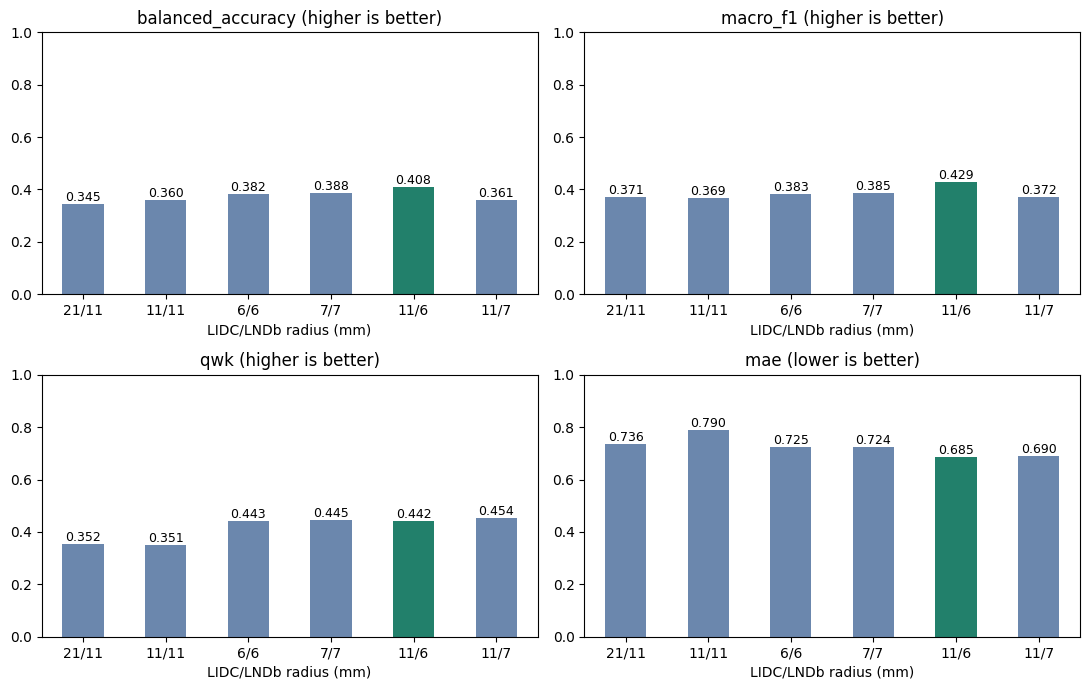

In [4]:
radius_results = results.loc[list(radius_runs)].rename(index=radius_runs)
display(radius_results.round(4))
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, metric in zip(axes.flat, METRICS):
    colors = ['#22806b' if radius == '11/6' else '#6b87ad' for radius in radius_results.index]
    radius_results[metric].plot.bar(ax=ax, color=colors, rot=0)
    ax.bar_label(ax.containers[0], fmt='%.3f', fontsize=9)
    ax.set(title=f"{metric} ({'lower' if metric == 'mae' else 'higher'} is better)", xlabel='LIDC/LNDb radius (mm)', ylim=(0, 1))
fig.tight_layout()
plt.show()

In [5]:
comparison = pd.DataFrame({'21/11': results.loc[BASELINE], '11/6': results.loc[CHOSEN]})
comparison['change'] = comparison['11/6'] - comparison['21/11']
display(comparison.round(4))
print('Changes within each held-out fold: 11/6 minus 21/11. Negative MAE changes are improvements.')
display((fold_scores[CHOSEN] - fold_scores[BASELINE]).round(4))

,21/11,11/6,change
balanced_accuracy,0.3455,0.4085,0.0630
macro_f1,0.3707,0.4294,0.0587
qwk,0.3523,0.4418,0.0895
mae,0.7359,0.6850,-0.0510


Changes within each held-out fold: 11/6 minus 21/11. Negative MAE changes are improvements.


,balanced_accuracy,macro_f1,qwk,mae
fold,,,,
1,0.1630,0.1433,0.1131,-0.0696
2,0.0442,0.0409,0.0446,-0.0440
3,0.0803,0.0791,0.2083,-0.0522
4,0.0216,0.0032,0.0547,-0.0807
5,0.0034,0.0155,0.0379,-0.0065


## 3. Did imbalance handling or changing the classifier help?

### Imbalance, feature selection and adding LIDC

All pooled runs below use 21/11 mm. LNDb-only runs use LNDb at 11 mm and remove LIDC from training. SMOTE and feature selection were fitted within training folds only. SMOTE improved balanced accuracy relative to the weighted baseline, but not all four metrics. **SMOTE has not yet been tested at 11/6 mm**, so this is not evidence that it cannot help the smaller-circle configuration.

In [6]:
display(results.loc[list(imbalance_runs)].rename(index=imbalance_runs).round(4))
print('SMOTE minus weighted RF, both at 21/11 mm:')
display((results.loc[SMOTE_RUN] - results.loc[BASELINE]).round(4).to_frame('change'))

,balanced_accuracy,macro_f1,qwk,mae
"RF, unweighted",0.3323,0.3473,0.3150,0.7425
"RF, balanced weights",0.3455,0.3707,0.3523,0.7359
"RF, balanced weights, k=100",0.3313,0.3497,0.3476,0.7386
"RF, SMOTE",0.3738,0.3630,0.3189,0.8013
"RF, SMOTE, k=100",0.3287,0.3173,0.3075,0.8340
"RF, SMOTE, k=500",0.3490,0.3416,0.3210,0.8144
Balanced RF,0.3717,0.3236,0.3042,0.8431
"RF, LNDb only, unweighted",0.3373,0.3548,0.2985,0.7464
"RF, LNDb only, balanced weights",0.3560,0.3726,0.3237,0.7503


SMOTE minus weighted RF, both at 21/11 mm:


,change
balanced_accuracy,0.0283
macro_f1,-0.0077
qwk,-0.0334
mae,0.0654


### Original-only features

These runs use 21/11 mm and balanced class weights. The RF comparison isolates the removal of filtered-image features. Logistic L1 and XGBoost were tested only on the 93 Original features, with fixed hyperparameters. These results do not show that other classifiers, tuned settings or Original features at smaller radius values cannot help.

In [7]:
display(results.loc[list(original_runs)].rename(index=original_runs).round(4))

,balanced_accuracy,macro_f1,qwk,mae
"RF, all 930 features",0.3455,0.3707,0.3523,0.7359
"RF, Original",0.3092,0.3287,0.2531,0.8484
"Logistic L1, Original",0.3277,0.2692,0.2966,0.9386
"XGBoost, Original",0.3008,0.2582,0.2130,0.9399


## 4. What information do the data and errors reveal?

### Class frequencies

LIDC and LNDb have different target distributions. Classes 4 and 5 are scarce in LNDb, so their recall is based on few cases. This is a plausible contributor to difficult generalization, not a measured causal effect.

,LIDC,LNDb
class,,
1,286,213
2,608,254
3,1249,209
4,384,71
5,110,18


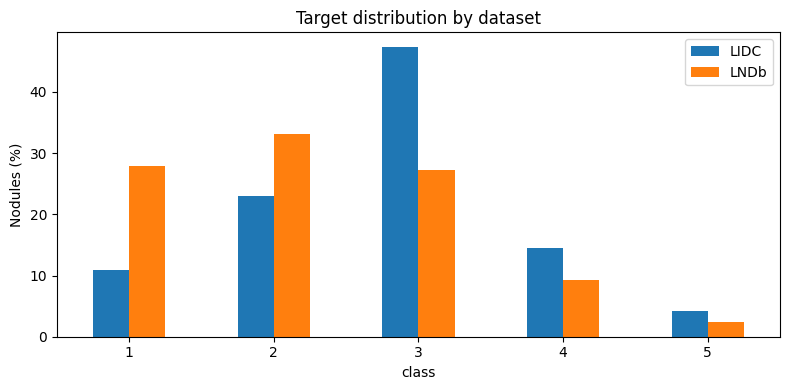

In [8]:
lidc_targets = pd.read_csv(ROOT / 'data/processed/lidc_nodule_targets.csv')
counts = pd.DataFrame({
    'LIDC': lidc_targets[TARGET].value_counts().reindex(CLASSES, fill_value=0),
    'LNDb': reference[TARGET].value_counts().reindex(CLASSES, fill_value=0),
})
counts.index.name = 'class'
display(counts)
percentages = counts.div(counts.sum()).mul(100)
percentages.plot.bar(rot=0, ylabel='Nodules (%)', title='Target distribution by dataset', figsize=(8, 4))
plt.tight_layout()
plt.show()

### Circle sizes versus nodule size estimates

The old circles had diameters of 42 mm in LIDC and 22 mm in LNDb. The 11/6 configuration uses 22/12 mm diameters. Larger circles include more surrounding tissue, which is a plausible explanation for the sensitivity to radius values.

LIDC size is the maximum reader diameter per nodule divided by two. LNDb uses half the grouped equivalent-sphere diameter (`DiamEq_Rad`). These are **different size definitions**. Percentages below describe size estimates, not guaranteed nodule coverage by a centroid-centred circle. LNDb findings below 3 mm do not have segmentation-derived volume estimates.

In [9]:
annotations = pd.read_csv(ROOT / 'data/processed/lidc_annotations_clean.csv')
lidc_radius = annotations.groupby(['patient_id', 'series_uid', 'nodule_id']).diameter.max() / 2
size_values = {'LIDC': lidc_radius}
if (LNDB_DIR / 'allNods.csv').exists():
    findings = pd.read_csv(LNDB_DIR / 'allNods.csv')
    sizes = targets[KEYS].merge(findings[KEYS + ['DiamEq_Rad']], on=KEYS, validate='one_to_one')
    size_values['LNDb'] = sizes.DiamEq_Rad / 2
else:
    print('LNDb size analysis skipped: allNods.csv is not available in LNDB_DIR.')
size_rows = {}
for dataset, values in size_values.items():
    size_rows[dataset] = {'nodules': len(values), 'median radius (mm)': values.median(), 'P95 radius (mm)': values.quantile(.95), 'P99 radius (mm)': values.quantile(.99)}
    size_rows[dataset].update({f'estimated radius <= {r} mm (%)': 100 * values.le(r).mean() for r in [6, 7, 11]})
display(pd.DataFrame.from_dict(size_rows, orient='index').round(2))

,nodules,median radius (mm),P95 radius (mm),P99 radius (mm),estimated radius <= 6 mm (%),estimated radius <= 7 mm (%),estimated radius <= 11 mm (%)
LIDC,2637,4.18,13.93,20.37,75.09,80.77,91.70
LNDb,765,2.28,5.69,10.93,95.69,97.39,98.95


### Which classes remain difficult?

Compare the old weighted RF with the smaller-circle weighted RF. **Recall** asks how many true cases of a class are recovered. **Precision** asks how often a prediction of that class is correct. Prediction counts reveal whether the model favours some classes.

In [10]:
y = reference[TARGET]
old = predictions[BASELINE].prediction
new = predictions[CHOSEN].prediction
class_errors = pd.DataFrame({
    'true cases': y.value_counts().reindex(CLASSES, fill_value=0),
    'predicted 21/11': old.value_counts().reindex(CLASSES, fill_value=0),
    'predicted 11/6': new.value_counts().reindex(CLASSES, fill_value=0),
    'recall 21/11': recall_score(y, old, labels=CLASSES, average=None, zero_division=0),
    'recall 11/6': recall_score(y, new, labels=CLASSES, average=None, zero_division=0),
    'precision 11/6': precision_score(y, new, labels=CLASSES, average=None, zero_division=0),
}, index=CLASSES)
class_errors.index.name = 'class'
display(class_errors.round(3))

,true cases,predicted 21/11,predicted 11/6,recall 21/11,recall 11/6,precision 11/6
class,,,,,,
1,213,163,158,0.502,0.545,0.734
2,254,390,344,0.594,0.563,0.416
3,209,195,228,0.282,0.364,0.333
4,71,10,21,0.070,0.127,0.429
5,18,7,14,0.278,0.444,0.571


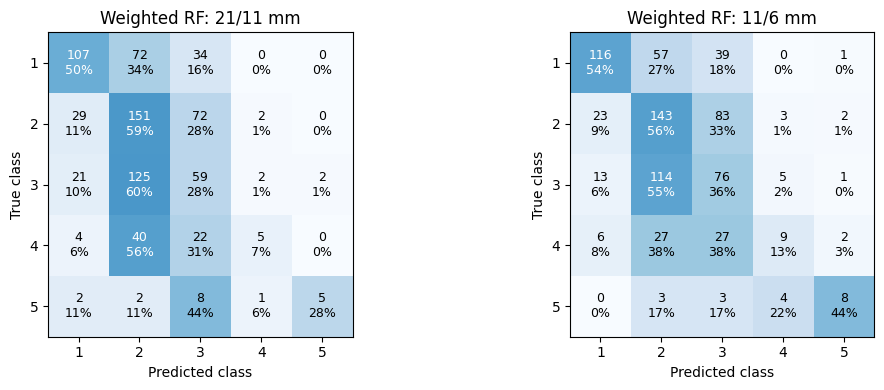

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, predicted, title in zip(axes, [old, new], ['Weighted RF: 21/11 mm', 'Weighted RF: 11/6 mm']):
    matrix = confusion_matrix(y, predicted, labels=CLASSES)
    normalized = matrix / matrix.sum(axis=1, keepdims=True)
    ax.imshow(normalized, cmap='Blues', vmin=0, vmax=1)
    for row in range(5):
        for col in range(5):
            ax.text(col, row, f'{matrix[row, col]}\n{normalized[row, col]:.0%}', ha='center', va='center', color='white' if normalized[row, col] > .5 else 'black', fontsize=9)
    ax.set(xticks=range(5), yticks=range(5), xticklabels=CLASSES, yticklabels=CLASSES, xlabel='Predicted class', ylabel='True class', title=title)
fig.tight_layout()
plt.show()

In [12]:
error_rows = {}
for name in [BASELINE, CHOSEN, SMOTE_RUN]:
    error = predictions[name].prediction - y
    error_rows[labels[name]] = {
        'exact (%)': 100 * error.eq(0).mean(),
        'within one class (%)': 100 * error.abs().le(1).mean(),
        'errors of 2+ classes (n)': int(error.abs().ge(2).sum()),
        'underestimated (%)': 100 * error.lt(0).mean(),
        'overestimated (%)': 100 * error.gt(0).mean(),
        'true 4/5 underestimated (%)': 100 * error[y.ge(4)].lt(0).mean(),
    }
display(pd.DataFrame.from_dict(error_rows, orient='index').round(2))
paired = pd.Series({
    'smaller absolute error with 11/6': int((new - y).abs().lt((old - y).abs()).sum()),
    'same absolute error': int((new - y).abs().eq((old - y).abs()).sum()),
    'larger absolute error with 11/6': int((new - y).abs().gt((old - y).abs()).sum()),
})
display(paired.to_frame('findings'))

,exact (%),within one class (%),errors of 2+ classes (n),underestimated (%),overestimated (%),true 4/5 underestimated (%)
"RF balanced, radius 21/11",42.75,84.97,115,33.20,24.05,88.76
"RF balanced, radius 11/6",46.01,87.19,98,28.76,25.23,78.65
"RF, SMOTE",42.22,81.96,138,41.31,16.47,77.53


,findings
smaller absolute error with 11/6,148
same absolute error,500
larger absolute error with 11/6,117


### Reader agreement and errors

A single rating is not reader consensus. Separate single-reader nodules from multi-reader nodules with equal or different ratings. Compare recall **within each class**, since class imbalance can distort an overall agreement comparison. Small subgroups and selection differences mean this is descriptive, not proof that disagreement causes errors.

In [13]:
reader_data = targets.merge(predictions[CHOSEN][KEYS + ['prediction']], on=KEYS, validate='one_to_one')
ratings = reader_data.ratings.map(ast.literal_eval)
np.testing.assert_array_equal(np.floor(ratings.map(np.mean) + .5).astype(int), reader_data[TARGET])
reader_data['reader_group'] = [
    'single reader' if len(values) == 1 else 'multiple, agree' if min(values) == max(values) else 'multiple, disagree'
    for values in ratings
]
reader_data['correct'] = reader_data.prediction.eq(reader_data[TARGET])
reader_summary = reader_data.groupby([TARGET, 'reader_group']).agg(n=('correct', 'size'), recall=('correct', 'mean'))
display(reader_summary.round(3))

n  recall
target_classification_mean reader_group                   
1                          multiple, agree      32   0.969
                           multiple, disagree    5   0.400
                           single reader       176   0.472
2                          multiple, agree      23   0.478
                           multiple, disagree   44   0.568
                           single reader       187   0.572
3                          multiple, agree      20   0.350
                           multiple, disagree   62   0.355
                           single reader       127   0.370
4                          multiple, agree       7   0.429
                           multiple, disagree   18   0.056
                           single reader        46   0.109
5                          multiple, agree       5   0.200
                           multiple, disagree    5   0.600
                           single reader         8   0.500

## 5. Are different LNDb IDs hiding the same CT?

### Fast shortlist: raw size and CRC

Read only the ZIP file directory, without decompressing CTs. Equal raw byte length and CRC identify **candidates**, not SHA-256-confirmed copies. This audit covers only the CT IDs in our saved LNDb training folds. Copies within the competition test set or between training and test scans have not been checked, nor have near-duplicate scans. Missing ZIPs are reported rather than counted as unique. Repeated folders with the same ID are a different issue: the extraction selects one CT per ID.

In [14]:
fold_lookup = patient_folds.set_index('LNDbID').fold.to_dict()
groups, missing = {}, []
for scan_id in fold_lookup:
    path = LNDB_DIR / f'LNDb-{scan_id:04d}.zip'
    if not path.exists():
        missing.append(scan_id)
        continue
    with ZipFile(path) as archive:
        raw = next(info for info in archive.infolist() if info.filename.endswith('.raw'))
    groups.setdefault((raw.file_size, raw.CRC), []).append(scan_id)
candidates = [ids for ids in groups.values() if len(ids) > 1]
candidate_table = pd.DataFrame([
    {'CT IDs': ids, 'folds': [fold_lookup[i] for i in ids], 'different folds': len({fold_lookup[i] for i in ids}) > 1}
    for ids in candidates
], columns=['CT IDs', 'folds', 'different folds'])
print(f'Checked {len(fold_lookup) - len(missing)}/{len(fold_lookup)} CT IDs. Candidate groups: {len(candidates)}.')
if missing:
    print('Missing ZIPs, audit incomplete:', missing)
display(candidate_table)

Checked 212/212 CT IDs. Candidate groups: 11.


,CT IDs,folds,different folds
0,"[161, 181]","[4, 3]",True
1,"[162, 182]","[3, 4]",True
2,"[163, 183]","[5, 2]",True
3,"[164, 184]","[2, 4]",True
4,"[165, 185]","[1, 3]",True
5,"[168, 188]","[4, 3]",True
6,"[169, 189]","[5, 4]",True
7,"[174, 194]","[5, 1]",True
8,"[175, 195]","[4, 4]",False
9,"[179, 198]","[5, 3]",True


### Confirm the candidates with SHA-256 and image headers

SHA-256 requires reading the complete raw image. Only shortlisted candidates are decompressed, in small chunks, without extracting files to disk. The full hashes are printed so their equality is visible. The `.mhd` headers are also compared, excluding the raw filename, to verify equal geometry and interpretation.

This proves equality of the **local input images**, not where the copies originated. We have not compared these volumes against the official archives. No CTs are deleted, merged or moved between folds.

In [15]:
hash_rows, verified_rows = [], []
for ids in candidates:
    hashes, headers = [], []
    for scan_id in ids:
        digest = hashlib.sha256()
        with ZipFile(LNDB_DIR / f'LNDb-{scan_id:04d}.zip') as archive:
            raw = next(name for name in archive.namelist() if name.endswith('.raw'))
            mhd = next(name for name in archive.namelist() if name.endswith('.mhd'))
            header = archive.read(mhd).decode()
            headers.append(tuple(line.strip() for line in header.splitlines() if not line.strip().startswith('ElementDataFile')))
            with archive.open(raw) as image:
                for chunk in iter(lambda: image.read(4 * 1024 * 1024), b''):
                    digest.update(chunk)
        sha = digest.hexdigest()
        hashes.append(sha)
        hash_rows.append({'LNDbID': scan_id, 'fold': fold_lookup[scan_id], 'SHA-256': sha})
        print(f'LNDb-{scan_id:04d}, fold {fold_lookup[scan_id]}, SHA-256: {sha}', flush=True)
    verified_rows.append({
        'CT IDs': ids, 'folds': [fold_lookup[i] for i in ids],
        'same SHA-256': len(set(hashes)) == 1, 'same image header': len(set(headers)) == 1,
        'different folds': len({fold_lookup[i] for i in ids}) > 1,
    })
hash_table = pd.DataFrame(hash_rows, columns=['LNDbID', 'fold', 'SHA-256'])
verified = pd.DataFrame(verified_rows, columns=['CT IDs', 'folds', 'same SHA-256', 'same image header', 'different folds'])
display(verified)
confirmed = verified.loc[verified['same SHA-256'].eq(True) & verified['same image header'].eq(True)]
print(f'Confirmed identical groups: {len(confirmed)}. Groups crossing folds: {int(confirmed["different folds"].sum())}.')

LNDb-0161, fold 4, SHA-256: 4c031cad95be26ba66cb7393b3e81e640ab456f6213c6458c1a2c8241ad70164


LNDb-0181, fold 3, SHA-256: 4c031cad95be26ba66cb7393b3e81e640ab456f6213c6458c1a2c8241ad70164


LNDb-0162, fold 3, SHA-256: a12225f44d1579ce763a4e061c5d08a14e3aab28d720056770d8f7a44d796425


LNDb-0182, fold 4, SHA-256: a12225f44d1579ce763a4e061c5d08a14e3aab28d720056770d8f7a44d796425


LNDb-0163, fold 5, SHA-256: 0b9b89790409c2cf56a47a06c76e209499c7c75df3d8b9100ca6d84a959fc222


LNDb-0183, fold 2, SHA-256: 0b9b89790409c2cf56a47a06c76e209499c7c75df3d8b9100ca6d84a959fc222


... (14 outputs left out)

LNDb-0225, fold 4, SHA-256: 7b16d2a6e4b0b997e2d9c12cb269596fbc54453bc91ebc0a0db5f5d81e9208ca


LNDb-0226, fold 2, SHA-256: 7b16d2a6e4b0b997e2d9c12cb269596fbc54453bc91ebc0a0db5f5d81e9208ca


,CT IDs,folds,same SHA-256,same image header,different folds
0,"[161, 181]","[4, 3]",True,True,True
1,"[162, 182]","[3, 4]",True,True,True
2,"[163, 183]","[5, 2]",True,True,True
3,"[164, 184]","[2, 4]",True,True,True
4,"[165, 185]","[1, 3]",True,True,True
5,"[168, 188]","[4, 3]",True,True,True
6,"[169, 189]","[5, 4]",True,True,True
7,"[174, 194]","[5, 1]",True,True,True
8,"[175, 195]","[4, 4]",True,True,False
9,"[179, 198]","[5, 3]",True,True,True


Confirmed identical groups: 11. Groups crossing folds: 10.


### Do repeated images also create identical model inputs?

Check exact equality of all 930 features in the 6 mm LNDb CSV. Different centroids or annotation sets on repeated scans can produce different features, so this is not a replacement for the CT hash check. Different targets for identical features show conflicting supervision, but do not by themselves prove an annotation or preparation error: readers can disagree.

In [16]:
table = pd.read_csv(ROOT / 'data/lndb_circle_r6_hu.csv')
feature_columns = table.filter(regex=r'_(firstorder|glcm|glrlm|glszm|gldm|ngtdm)_').columns.tolist()
assert len(feature_columns) == 930
repeated = table.loc[table[feature_columns].duplicated(keep=False)].copy()
if len(repeated):
    repeated['feature group'] = repeated.groupby(feature_columns, sort=False, dropna=False).ngroup() + 1
    display(repeated[['feature group', *KEYS, 'fold', TARGET, 'ratings', 'x', 'y', 'z']].sort_values(['feature group', *KEYS]).round(3))
    conflicts = repeated.groupby('feature group')[TARGET].nunique().gt(1)
    print(f'{len(repeated)} findings have identical feature vectors. {int(conflicts.sum())} groups have different targets.')
else:
    print('No exactly repeated feature vectors.')

,feature group,LNDbID,FindingID,fold,target_classification_mean,ratings,x,y,z
410,1,165,1,1,2,"[1.0, 3.0]",-98.042,-59.503,-997.123
464,1,185,2,3,2,"[2.0, 2.0]",-98.042,-59.503,-997.123
411,2,165,2,1,3,"[1.0, 5.0]",-65.972,-188.448,-1043.844
465,2,185,3,3,5,"[4.0, 5.0]",-65.972,-188.448,-1043.844
421,3,168,3,4,3,"[3.0, 3.0]",-77.069,-57.431,-1118.260
470,3,188,4,3,3,[3.0],-77.069,-57.431,-1118.260
425,4,168,7,4,3,[3.0],151.700,-130.804,-1140.260
471,4,188,5,3,2,[2.0],151.700,-130.804,-1140.260
442,5,175,5,4,4,[4.0],95.561,-141.067,-1009.495
481,5,195,2,4,3,[3.0],95.561,-141.067,-1009.495


10 findings have identical feature vectors. 3 groups have different targets.


## 6. What can we conclude, and what remains uncertain?

- **ROI choice mattered:** 11/6 mm improved all four overall metrics relative to 21/11 mm. It has the best saved balanced accuracy, macro F1 and MAE, while 11/7 mm has the best QWK. More surrounding tissue is a plausible mechanism, not a proven unique cause.
- **Class 4 remains difficult:** its recall rose from about 7% to 13%, but most cases are still missed. Class 5 recall is based on only 18 nodules. Class counts and confusion matrices are more informative than a single average score.
- **SMOTE has a trade-off:** it improved balanced accuracy at 21/11 mm while worsening the other three metrics relative to weighted RF. Its effect at 11/6 mm has not been measured.
- **Original-only was worse in the tested configuration:** this does not rule out other feature subsets, classifiers or properly nested tuning.
- **Ratings are not objective diagnoses:** disagreement and small class counts may limit learnable signal. The reader analysis describes associations, not isolated causes.
- **Repeated local CTs undermine fold independence:** equal SHA-256 and image headers confirm the displayed copies. Cross-fold copies permit the same examination to appear in training and validation. This does not establish their origin or show that they are the main cause of poor performance.

All comparisons remain provisional because of cross-fold CT copies and because configurations were selected using these same five folds. The notebook intentionally leaves the original data and saved fold assignments unchanged.